In [1]:
import sys
import os

# Ensure local packages (models, lib_QEC) are importable
for p in [os.path.abspath(".." ), os.path.abspath(".")]:
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator

from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

import matplotlib.pyplot as plt

# for exact classical simulation
from scipy.linalg import expm
from scipy.integrate import solve_ivp

# Import Lipkin model functions
from models.Lipkin import diabolic_points, qpt_line, LipkinHamiltonian
from models.Lipkin_onehot import OptimizedLipkinSimulation

# QEC / mitigation utilities (simulator-only)
from lib_QEC.twirling import apply_partial_twirling, TwirlingConfig
from lib_QEC.pauli import is_one_hot_bitstring, post_select_counts
from lib_QEC.qedc_422 import encode_422
from lib_QEC.circuits import exp_pauli
from lib_QEC.pec import (
    reduce_channel_422,
    invert_pauli_channel,
    pec_expectation_from_values,
    quasiprobability_overhead,
 )

In [2]:
# Simulator-only noise model (no hardware backends, no qiskit-ibm-runtime).

noise_model_name = "toy_depolarizing+readout"

# Tune these to roughly match a NISQ regime
p_1q = 0.001   # 1-qubit depolarizing per gate
p_2q = 0.01    # 2-qubit depolarizing per CX gate
p_ro = 0.02    # symmetric readout flip probability

noise_model = NoiseModel()

# Add 1Q depolarizing noise to a broad set of common 1Q gate names.
# (Transpilation may choose 'u'/'u3' etc depending on versions/backends.)
_gates_1q = [
    "id", "u", "u1", "u2", "u3",
    "x", "sx", "rz", "h", "s", "sdg", "rx", "ry",
 ]
noise_model.add_all_qubit_quantum_error(depolarizing_error(p_1q, 1), _gates_1q)

# 2Q gates (CX after decomposition)
noise_model.add_all_qubit_quantum_error(depolarizing_error(p_2q, 2), ["cx"])

# Readout noise
ro_err = ReadoutError([[1 - p_ro, p_ro], [p_ro, 1 - p_ro]])
noise_model.add_all_qubit_readout_error(ro_err)

print(f"Using Aer noise model: {noise_model_name}")
print(f"  p_1q={p_1q}, p_2q={p_2q}, p_ro={p_ro}")
print(f"  basis gates: {noise_model.basis_gates}")

Using Aer noise model: toy_depolarizing+readout
  p_1q=0.001, p_2q=0.01, p_ro=0.02
  basis gates: ['cx', 'h', 'id', 'rx', 'ry', 'rz', 's', 'sdg', 'sx', 'u', 'u1', 'u2', 'u3', 'x']


# Parameters

In [3]:
# Lipkin model parameters
N = 2 # system size

# Time evolution
x0, y0 = -0.5, 0.0 # initial point
xf, yf = -0.3, 1.5 # final point
T = 10.0           # final driving time
n_steps = 5        # steps in time
trotter_order = 2   # used in SuzukiTrotter decomposition on QC

# Circuit construction method
use_optimized_trotter = True  # True: use optimized one-hot mapping (efficient XY gates)
                               # False: use default Qiskit PauliEvolutionGate

# Transpilation (Aer)
qc_optimization_level = 3  # optimization level for transpilation
approximation_degree = 1.0 # 1.0=no approximation, 0.0=maximal approximation

# Sampling
number_of_shots = 4000

# Error-suppression toggles
enable_twirling = True         # Partial Pauli twirling (averaged over many twirls)
n_twirls = 8                   # number of twirl instances to average (keep small for speed)

# Continuous classical simulation (slow)
rerun_continuous_simulation = True

# Aer simulator shots
number_of_shots_aer = number_of_shots
number_of_shots_aer_noisy = 10000

## Path Definition in (x,y) Parameter Space

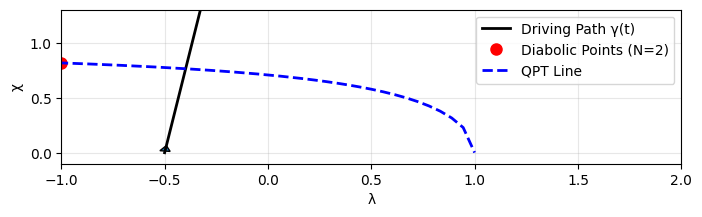

In [4]:
def gamma(t, T):
    """Define the driving path gamma(t) in (x,y) parameter space."""
    # Linear path from x0, y0 to xf, yf
    x = x0 + (xf - x0) * t / T
    y = y0 + (yf - y0) * t / T
    
    return x, y

ts = np.linspace(0, T, 100)
xs, ys = zip(*[gamma(t, T) for t in ts])

plt.figure(figsize=(8, 6))
# Plot driving path
plt.plot(xs, ys, 'k-', linewidth=2, label='Driving Path γ(t)')
plt.arrow(xs[0], ys[0], xs[1]-xs[0], ys[1]-ys[0], head_width=0.05, head_length=0.05)

# Plot diabolic points
dp = diabolic_points(N)
plt.plot(dp[:, 0], dp[:, 1], 'ro', markersize=8, label=f'Diabolic Points (N={N})')

# Plot QPT line
lambda_vals = np.linspace(-10, 0.999999, 200)
chi_vals = qpt_line(lambda_vals)
plt.plot(lambda_vals, chi_vals, 'b--', linewidth=2, label='QPT Line')
# set image resolution to 200x600
plt.gcf().set_size_inches(8, 2)
plt.xlabel('λ')
plt.ylabel('χ')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(-1, 2)
plt.ylim(-0.1, 1.3)
plt.show()

## Hamiltonian definition

### Original N+1 dim implementation

In [5]:
dim_H = N + 1  # Number of physical states in the j=N/2 sector
num_qubits_orig = int(np.ceil(np.log2(dim_H)))

def lipkin_in_time(t: float, T: float, atol: float = 1e-10) -> SparsePauliOp:
    """Build Lipkin Hamiltonian as SparsePauliOp with proper padding to 2^n dimension."""
    x, y = gamma(t, T)
    H_physical = LipkinHamiltonian(N, λ=x, χ=y)
    
    # Pad to 2^n for quantum circuit compatibility
    dim = N + 1
    padded_dim = 2**num_qubits_orig
    H_padded = np.zeros((padded_dim, padded_dim), dtype=complex)
    H_padded[:dim, :dim] = H_physical
    
    # Add large energy offset to non-physical states
    # This keeps them out of the low-energy subspace
    E_max = np.max(np.diag(H_physical.real))  # Maximum physical energy
    offset = E_max + 1e10  # Large energy gap
    for i in range(dim, padded_dim):
        H_padded[i, i] = offset
    
    return SparsePauliOp.from_operator(Operator(H_padded)).simplify(atol=atol)

print(f'Lipkin model: N = {N}')
print(f'Hilbert space dimension (physical): {dim_H}')
print(f'Number of qubits: {num_qubits_orig}')
print(f'Padded dimension: {2**num_qubits_orig}')
print(f'Number of terms in Hamiltonian at t=0: {len(lipkin_in_time(0, T, atol=1e-10))}')

Lipkin model: N = 2
Hilbert space dimension (physical): 3
Number of qubits: 2
Padded dimension: 4
Number of terms in Hamiltonian at t=0: 6


### Lipkin one-hot mapping

In [6]:
dim_H = N + 1  # Number of physical states in the j=N/2 sector
sim = OptimizedLipkinSimulation(N)
# sim = GrayCodeLipkin(N)
num_qubits = sim.num_qubits # N+1 for one-hot encoding
print(f'Using {num_qubits} qubits for optimized encoding.')

Using 3 qubits for optimized encoding.


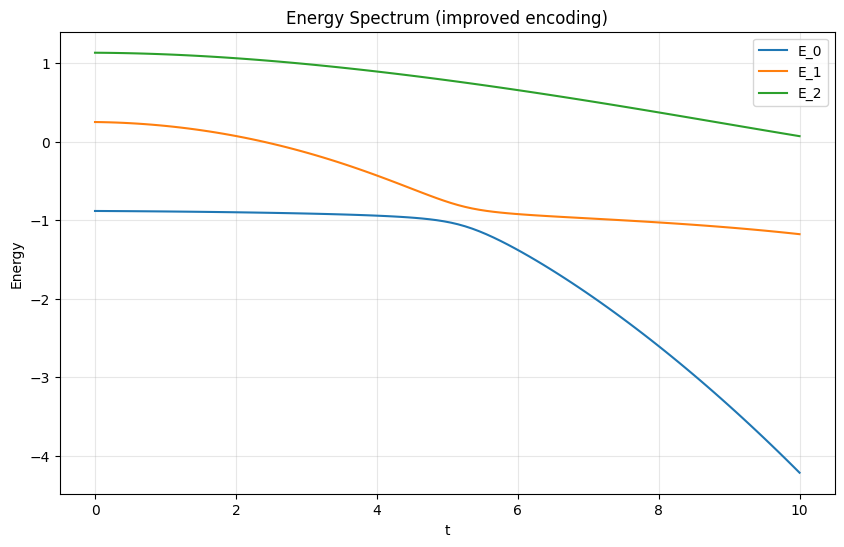

In [7]:
# Plot spectrum using OptimizedLipkinSimulation from lipkin_optimized_v3.py
n_points = 100
t_values = np.linspace(0, T, n_points)
eigenvalues_optimized = np.zeros((n_points, dim_H))
for i, t in enumerate(t_values):
    x, y = gamma(t, T)
    H_opt = sim.hamiltonian_matrix(x, y)
    evals_opt = np.linalg.eigvalsh(H_opt)
    eigenvalues_optimized[i, :] = evals_opt[:dim_H]

fig, ax = plt.subplots(figsize=(10, 6))
for j in range(dim_H):
    ax.plot(t_values, eigenvalues_optimized[:, j], label=f'E_{j}')

ax.set_xlabel('t')
ax.set_ylabel('Energy')
ax.set_title('Energy Spectrum (improved encoding)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## Time evolution circuit

Uses statevector simulation to preserve full quantum information, then project onto energy eigenbasis.

- Usually we start from some easily preparable state, so the first step would be ommitted. Here the initial state is set to be the ground state of $H(0)$, so we have the freedom. But it is cheating.
- Classical diagonalization is also used at the final time, this could be replaced by quantum state tomography to do the computation fully on QC. However, practically computational basis is good enough for many practical applications, here we just want to intuitively understand the result. Or we would measure in the end some observable (like total magnetization).

At final time we have $|\psi\rangle = \sum_i c_i |E_i\rangle$ in the energy basis, for $c_i = \langle E_i|\psi\rangle$.

### Create the circuit with initial position and Trotterization

In [8]:
# Build the circuit using the selected method
qc = sim.build_adiabatic_circuit(gamma, T, n_steps, use_optimized=use_optimized_trotter, trotter_order=trotter_order)

print(f"Circuit summary:")
print(f"N: {N}")
print(f"Method: {'Optimized (efficient XY gates)' if use_optimized_trotter else 'Default Qiskit (PauliEvolutionGate) with SuzukiTrotter of order ' + str(trotter_order)}")
print(f"Number of qubits: {num_qubits}")
print(f"Depth: {qc.decompose().depth()}")
print(f"Gates: {qc.decompose().size()}")
# qc.decompose().decompose().draw('mpl', fold=-1)

Circuit summary:
N: 2
Method: Optimized (efficient XY gates)
Number of qubits: 3
Depth: 136
Gates: 237


### Get the final Hamiltonian and its eigenbasis

In [9]:
xf, yf = gamma(T, T)
Hf_matrix = sim.hamiltonian_matrix(xf, yf)
evalsf, evecsf = np.linalg.eigh(Hf_matrix)

print(f"Physical eigenvalues at T={T}:")
for i, ev in enumerate(evalsf[:dim_H]):
    print(f"  E_{i} = {ev:.6f}")

Physical eigenvalues at T=10.0:
  E_0 = -4.216582
  E_1 = -1.178417
  E_2 = 0.069998


In [10]:
# Create projector observables using one-hot embedding
# In one-hot encoding, physical state |m⟩ corresponds to computational state with bit m set
# i.e., state |m⟩ → |0...010...0⟩ with 1 at position m (index 2^m in computational basis)

projectors = sim.energy_projectors(xf, yf)
print(f"Created {len(projectors)} projectors onto final energy eigenstates.")

Created 3 projectors onto final energy eigenstates.


## Transpile and run on Aer (noisy/noiseless)

In [11]:
# Transpile the Lipkin evolution circuit for Aer simulation.
# We decompose first to remove XXPlusYYGate before later adding the final-basis unitary.

qc_decomposed = qc.decompose()

qc_transpiled = transpile(
    qc_decomposed,
    basis_gates=noise_model.basis_gates,
    optimization_level=qc_optimization_level,
    approximation_degree=approximation_degree,
    seed_transpiler=42,
 )

print(f"Transpiled evolution circuit: {qc_transpiled.size()} gates, depth {qc_transpiled.depth()}")
print(f"Qubits: {qc_transpiled.num_qubits}")

Transpiled evolution circuit: 98 gates, depth 65
Qubits: 3


### Aer Simulator (noiseless quantum simulation)

In [12]:
# Aer Simulator without noise - simulates the circuit with sampling (like real QC but no noise)

# Build the measurement circuit with energy basis rotation
# For one-hot encoding, we embed U_dagger into the full 2^(N+1) space.

full_dim = 2**num_qubits
one_hot_indices = [1 << m for m in range(dim_H)]  # [1, 2, 4, 8, ...] for one-hot states

# Build the transformation matrix in the full computational basis
U_dagger_full = np.eye(full_dim, dtype=complex)
for i, idx_i in enumerate(one_hot_indices):
    for j, idx_j in enumerate(one_hot_indices):
        U_dagger_full[idx_i, idx_j] = evecsf.conj().T[i, j]

# Check unitarity
is_unitary = np.allclose(U_dagger_full @ U_dagger_full.conj().T, np.eye(full_dim), atol=1e-10)
print(f"U_dagger_full is unitary: {is_unitary}")

# Ensure XXPlusYYGate is decomposed before adding the unitary
try:
    qc_decomposed
except NameError:
    qc_decomposed = qc.decompose()

qc_aer = qc_decomposed.copy()
qc_aer.unitary(U_dagger_full, range(num_qubits), label='U†')
qc_aer.measure_all()

# Run on noiseless Aer simulator
aer_noiseless = AerSimulator(method='statevector', seed_simulator=42)

# Use optimization_level=0 to prevent decomposition of the large unitary
qc_aer_transpiled = transpile(qc_aer, aer_noiseless, optimization_level=0)

job_aer = aer_noiseless.run(qc_aer_transpiled, shots=number_of_shots_aer)
counts_aer = job_aer.result().get_counts()

# Convert counts to probabilities - extract one-hot states
total_shots_aer = sum(counts_aer.values())
aer_probs = np.zeros(dim_H)
for m in range(dim_H):
    bitstring = format(one_hot_indices[m], f'0{num_qubits}b')
    aer_probs[m] = counts_aer.get(bitstring, 0) / total_shots_aer

# Normalize
aer_prob_sum = np.sum(aer_probs)
if aer_prob_sum > 0:
    aer_probs_normalized = aer_probs / aer_prob_sum
else:
    aer_probs_normalized = aer_probs

print(f"Aer Simulator (noiseless, {total_shots_aer} shots):")
for i, prob in enumerate(aer_probs_normalized):
    print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

# Check leakage to non-physical states
leakage = 1.0 - sum(counts_aer.get(format(idx, f'0{num_qubits}b'), 0) for idx in one_hot_indices) / total_shots_aer
print(f"  Leakage to non-physical states: {leakage:.6f}")

U_dagger_full is unitary: True
Aer Simulator (noiseless, 4000 shots):
  E_0 (E=-4.2166): 0.0575
  E_1 (E=-1.1784): 0.8180
  E_2 (E=0.0700): 0.1245
  Leakage to non-physical states: 0.000000


### Ideal (statevector, no sampling)



This is the same *trotterized* circuit as above, but evaluated exactly (no shot noise). It’s useful as a clean baseline between “Aer noiseless (shots)” and the classical references.


In [ ]:
# Ideal statevector evaluation of the same measurement circuit (no shots)
qc_ideal = qc_decomposed.copy()
qc_ideal.unitary(U_dagger_full, range(num_qubits), label="U†")
psi_final = Statevector.from_instruction(qc_ideal)
probs_full = np.abs(psi_final.data) ** 2
ideal_probs = np.array([probs_full[idx] for idx in one_hot_indices], dtype=float)
ideal_prob_sum = float(np.sum(ideal_probs))
ideal_probs_normalized = ideal_probs / ideal_prob_sum if ideal_prob_sum > 0 else ideal_probs

ideal_leakage = 1.0 - ideal_prob_sum
print("Ideal (statevector) energy populations:")
for i, prob in enumerate(ideal_probs_normalized):
    print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

print(f"  Leakage to non-physical states: {ideal_leakage:.6e}")

Ideal (statevector) energy populations:
  E_0 (E=-4.2166): 0.0641
  E_1 (E=-1.1784): 0.8043
  E_2 (E=0.0700): 0.1316
  Leakage to non-physical states: 4.440892e-16


### Aer Simulator with device noise model

### Leakage detection via the one-hot embedding

The Lipkin Hamiltonian acts on the $N+1$-dimensional collective spin sector $j=N/2$, which is embedded into $N+1$ physical qubits by the **one-hot mapping** $|m\rangle \mapsto |0\cdots 1\cdots 0\rangle$ (a single $1$ at position $m$). Any depolarizing error that flips a single qubit can produce a bitstring of Hamming weight $0$ or $2$ — these states are *outside* the physical Hilbert space.

The post-selection filter `is_one_hot_bitstring` (from `lib_QEC.pauli`) drops every shot whose bitstring has $\text{wt}(b) \neq 1$. This is a free, **ancilla-less error-detection scheme**, conceptually analogous to (but simpler than) the $[[4,2,2]]$ stabilizer code used in Part B. The survival probability `survival_onehot` is the fraction of shots inside the codespace; $1 - \text{survival\_onehot}$ is the *leakage* rate.

In [ ]:
# Aer Simulator WITH noise model (simulator-only).
#
# Part A — one-hot postselection mitigation.
# This cell extracts two quantities from the noisy shots:
#   * aer_noisy_probs_raw[m]            P(one-hot state m), no postselection
#                                       (the populations sum to 1 − leakage)
#   * aer_noisy_probs_postselected[m]   P(one-hot state m) renormalized over
#                                       one-hot bitstrings only (Hamming-weight-1
#                                       postselection — drops every leakage shot)
# survival_onehot is the fraction of shots that survive postselection (equivalently 1 − leakage).

def _counts_to_probs_raw_and_postselected(counts, one_hot_indices, num_qubits, dim_H):
    total = sum(counts.values())
    if total == 0:
        zeros = np.zeros(dim_H)
        return zeros, zeros, 0.0
    probs_raw = np.zeros(dim_H)
    for m in range(dim_H):
        bitstring = format(one_hot_indices[m], f'0{num_qubits}b')
        probs_raw[m] = counts.get(bitstring, 0) / total
    kept = float(np.sum(probs_raw))
    probs_post = probs_raw / kept if kept > 0 else probs_raw.copy()
    return probs_raw, probs_post, kept


def _run_noisy_counts(qc_to_run, seed):
    aer_noisy = AerSimulator(noise_model=noise_model, seed_simulator=seed)
    qc_t = transpile(
        qc_to_run,
        aer_noisy,
        optimization_level=0,  # keep the big unitary as a single instruction
        seed_transpiler=seed,
    )
    return aer_noisy.run(qc_t, shots=number_of_shots_aer_noisy).result().get_counts()


# Build (optionally twirled) evolution circuit, then rotate into final energy basis and measure
if enable_twirling:
    probs_raw_accum = np.zeros(dim_H)
    probs_post_accum = np.zeros(dim_H)
    survival_accum = 0.0
    for k in range(n_twirls):
        rng = np.random.default_rng(1234 + k)
        evo = apply_partial_twirling(qc_decomposed, rng=rng)
        qc_run = evo.copy()
        qc_run.unitary(U_dagger_full, range(num_qubits), label='U†')
        qc_run.measure_all()
        counts = _run_noisy_counts(qc_run, seed=9000 + k)
        pr, pp, surv = _counts_to_probs_raw_and_postselected(
            counts, one_hot_indices, num_qubits, dim_H
        )
        probs_raw_accum += pr
        probs_post_accum += pp
        survival_accum += surv
    aer_noisy_probs_raw = probs_raw_accum / n_twirls
    aer_noisy_probs_postselected = probs_post_accum / n_twirls
    survival_onehot = survival_accum / n_twirls
    print(f"Aer Simulator (noisy: {noise_model_name}, twirled avg over {n_twirls} runs):")
else:
    qc_run = qc_decomposed.copy()
    qc_run.unitary(U_dagger_full, range(num_qubits), label='U†')
    qc_run.measure_all()
    counts = _run_noisy_counts(qc_run, seed=9000)
    aer_noisy_probs_raw, aer_noisy_probs_postselected, survival_onehot = (
        _counts_to_probs_raw_and_postselected(counts, one_hot_indices, num_qubits, dim_H)
    )
    print(f"Aer Simulator (noisy: {noise_model_name}, single run):")

leakage_noisy = 1.0 - survival_onehot

print(f"  one-hot survival (postselection): {survival_onehot:.4f}")
print(f"  leakage to non-physical states:   {leakage_noisy:.4f}")
print()
print("  populations (raw vs. one-hot-postselected):")
header = "  " + "level".ljust(14) + "raw".rjust(12) + "postselected".rjust(16)
print(header)
for i in range(dim_H):
    label = f"E_{i} ({evalsf[i]:.3f})"
    print( "  " + label.ljust(14) + f"{aer_noisy_probs_raw[i]:.4f}".rjust(12) + f"{aer_noisy_probs_postselected[i]:.4f}".rjust(16))

Aer Simulator (noisy: toy_depolarizing+readout, twirled avg over 8 runs):
  one-hot survival (postselection): 0.6429
  leakage to non-physical states:   0.3571

  populations (raw vs. one-hot-postselected):
  level                  raw    postselected
  E_0 (-4.217)        0.0872          0.1357
  E_1 (-1.178)        0.4305          0.6696
  E_2 (0.070)         0.1251          0.1947


# Part B — Hybrid [[4,2,2]] QEDC + Partial Twirling + PEC
This section is a *self-contained* demonstration of the protocol from
**Zhong et al. (2025), "Combining Error Detection and Mitigation: A Hybrid
Protocol for Near-Term Quantum Simulation"**. It is run on a tiny 2-logical-qubit
driving problem so all the steps in `QEC_plan.md` (encoding, logical rotations,
partial twirling, post-selection, analytic noise channel, channel reduction, PEC
correction) can be shown end-to-end.

**Why a separate demo?** The Lipkin one-hot evolution in Part A uses $N+1$
physical qubits and a non-binary code structure. The article's [[4,2,2]] code
encodes exactly 2 logical qubits into 4 physical qubits and only directly fits
a 2-qubit logical state — so we use a small driven 2-logical-qubit problem here
that maps cleanly into the [[4,2,2]] block. The two parts demonstrate
*complementary* mitigation ideas:

| | Code | Mitigation | Cell |
|---|---|---|---|
| Part A | one-hot (Lipkin) | Hamming-weight-1 post-selection | already above |
| Part B | [[4,2,2]] QEDC | partial twirling + QEDC syndrome + PEC | below |

### The hybrid estimator (Zhong et al., Sec. II.C)

The hybrid protocol composes three near-term mitigation techniques. The full estimator is
$$\langle\hat A\rangle = \mathrm{Tr}\bigl[A\,\mathcal{N}^{-1}_\text{reduced}\circ\mathcal{Q}\circ\tilde{\mathcal{D}}\circ\tilde{\mathcal{U}}\circ\tilde{\mathcal{E}}(\rho_0)\bigr] \qquad \text{(Eq. 2.13)}$$
where $\tilde{\mathcal{E}}, \tilde{\mathcal{U}}, \tilde{\mathcal{D}}$ are the noisy encode / circuit / decode channels, $\mathcal{Q}$ is QEDC post-selection on the trivial syndrome, and $\mathcal{N}_\text{reduced}$ is the residual Pauli channel after dropping every Pauli that the [[4,2,2]] code can detect (anticommutes with $XXXX$ or $ZZZZ$). For the direct-sum form (Sec. IV.B):
$$\langle\hat A(\theta)\rangle = \sum_{j=1}^{16} c_j^\text{inv}(\theta)\,\mathrm{Tr}\bigl\{A\,\mathcal{P}_j\circ\mathcal{N}_\text{reduced}[\rho(\theta)]\bigr\} \qquad \text{(Eq. 4.5)}$$

**Why the three techniques compose well.** QEDC discards every shot whose syndrome flags a detectable Pauli error. The *remaining* logical channel $\mathcal{N}_\text{reduced}$ has many fewer Pauli terms than the bare $\mathcal{N}_\text{tot}$, so its quasi-probability inverse has a much smaller $\gamma^2 = \bigl(\sum_p |c_p^\text{inv}|\bigr)^2$. This is the central insight of Fig. 3 of Zhong et al. (2025): PEC on a QEDC-protected circuit beats PEC on a bare circuit by orders of magnitude in sampling overhead. Partial twirling restricted to the alphabet $\{I, X, Z\}$ further reduces twirling cost (8 of 9 pairs from $\{I,X,Z\}^2$ — the only ones that close under CX-conjugation) and matches superconducting-transmon hardware bias.

### Driving problem (2 logical qubits)

* Initial state: encoded $|\overline{00}\rangle$ (the $+1,+1$ eigenstate of
  $XXXX$ and $ZZZZ$).
* Logical unitary: $\overline{U}(\theta) = \exp(-i\,\theta/2 \cdot \bar Y_1 \bar X_2)$
  — a simplified UCC-type ansatz inspired by the article's Eq. (4.4).
* With the qubit ordering $q_\text{data} = [q_x, q_z, q_2, q_1]$, the encoded
  generator $\bar Y_1 \bar X_2$ becomes the 4-qubit Pauli `YXIZ` (Y on $q_1$,
  X on $q_2$, I on $q_z$, Z on $q_x$).

The four observables tracked below match the article's Fig. 11:

$$\langle\bar Z_1\rangle,\ \langle\bar Z_2\rangle,\ \langle\bar Z_1 \bar Z_2\rangle,\ \langle\bar X_1 \bar X_2\rangle$$

Ideal values (analytic):
$\langle\bar Z_1\rangle = \langle\bar Z_2\rangle = \cos\theta$,
$\langle\bar Z_1 \bar Z_2\rangle = 1$,
$\langle\bar X_1 \bar X_2\rangle = \sin\theta$.

### Pipeline (the numbered steps from `QEC_plan.md`)

1. **Encode** with `encode_422` (Fig. 1 left of article — proper encoder
   for an arbitrary 2-qubit logical input, not just $|\overline{00}\rangle$).
2. **Logical rotation** $\exp(-i\theta/2\,\bar Y_1\bar X_2)$ via `exp_pauli`.
3. **Partial twirling** with $\{I, X, Z\}$ averaged over `n_twirls_B` instances.
4. **Decode + measure** with `measure_decoded`; clbits 0,1 hold the syndrome
   and clbits 2,3 the logical Z/X readouts.
5. **QEDC post-select** the syndrome $00$ via `post_select_codespace_decoded`.
6. **Analytic Pauli fidelity** $f_A$ for each observable using
   `pauli_fidelity_through_clifford` (Heisenberg-propagate the observable
   backwards through the encoded circuit, multiplying by the per-gate
   depolarizing fidelity $(1-16 p_{2Q}/15)$ for each 2Q gate whose support
   carries non-trivial Pauli weight, and analogously $(1-4 p_{1Q}/3)$ for 1Q
   gates). This is the diagonal-Pauli limit of $\mathcal{N}_\text{reduced}$
   from the article's Sec. II.D.
7. **PEC correction**: $\langle A\rangle_\text{PEC} = \langle A\rangle_\text{QEDC} / f_A$.
   This is the diagonal-Pauli-channel collapse of Eq. (2.13) / Eq. (4.5).

In [15]:
# Part B, steps 1–5: build encoded circuit, run noiseless + noisy + QEDC post-select.

from qiskit import ClassicalRegister
from lib_QEC import (
    encode_422,
    decode_422,
    measure_decoded,
    post_select_codespace_decoded,
    codespace_survival_decoded,
    logical_expectation_from_counts,
    pauli_fidelity_through_clifford,
    pauli_fidelity_from_calibration,
    apply_partial_twirling,
    TwirlingConfig,
    exp_pauli,
    LOGICAL_OPS,
)

# ---- Part B configuration ----
n_thetas_B    = 13                           # θ samples on [0, 2π]
shots_B       = 8_000                        # shots per circuit
n_twirls_B    = 4                            # twirl instances to average
encoded_gen   = "YXIZ"                       # encoded Ȳ_1 X̄_2
B_q_data      = [0, 1, 2, 3]                 # [q_x, q_z, q_2, q_1]
theta_sweep_B = np.linspace(0.0, 2 * np.pi, n_thetas_B)

# Observables: (measurement basis, observable name in logical_expectation_from_counts)
B_observables = {
    "Z1":   ("ZZ", "Z1"),
    "Z2":   ("ZZ", "Z2"),
    "Z1Z2": ("ZZ", "Z1Z2"),
    "X1X2": ("XX", "X1X2"),
}


def build_encoded_body(theta, twirl_rng=None):
    """Step 1 + 2 + 3:  encoder → R̄(θ)  (optionally partially twirled).  No decode, no measure."""
    qc = QuantumCircuit(4, name=f"body_θ{theta:.3f}")
    encode_422(qc, B_q_data)
    exp_pauli(qc, encoded_gen, theta, qubits=B_q_data)
    if twirl_rng is not None:
        qc = apply_partial_twirling(
            qc, rng=twirl_rng, config=TwirlingConfig(("I", "X", "Z"))
        )
    return qc


def build_full_circuit(theta, twirl_rng, basis):
    """Step 1–4: encoded body → decode → basis change → measure all four qubits."""
    qc = build_encoded_body(theta, twirl_rng=twirl_rng)
    measure_decoded(qc, B_q_data, basis=basis)
    return qc


# -----------------------------------------------------------------------------
# Ideal expectations from statevector (no noise, no shot noise).
# -----------------------------------------------------------------------------

def _expectation_ideal(theta, basis, obs_name):
    body = build_encoded_body(theta, twirl_rng=None)
    finishing = QuantumCircuit(4)
    decode_422(finishing, B_q_data)
    if basis[0] == "X":
        finishing.h(2)
    if basis[1] == "X":
        finishing.h(3)
    sv = Statevector.from_instruction(body).evolve(finishing)
    probs = np.abs(sv.data) ** 2
    # Sum over post-selected (q_x = q_z = 0) bitstrings.
    total = 0.0
    acc = 0.0
    for idx in range(16):
        q_x = (idx >> 0) & 1
        q_z = (idx >> 1) & 1
        q_2 = (idx >> 2) & 1
        q_1 = (idx >> 3) & 1
        if q_x or q_z:
            continue
        if obs_name in ("Z1", "X1"):
            eig = 1 - 2 * q_1
        elif obs_name in ("Z2", "X2"):
            eig = 1 - 2 * q_2
        else:
            eig = 1 - 2 * ((q_1 + q_2) % 2)
        total += probs[idx]
        acc += eig * probs[idx]
    return acc / total if total > 0 else 0.0


ideal_values_B = {k: np.zeros(n_thetas_B) for k in B_observables}
for ti, theta in enumerate(theta_sweep_B):
    for obs_key, (basis, obs_name) in B_observables.items():
        ideal_values_B[obs_key][ti] = _expectation_ideal(theta, basis, obs_name)

# -----------------------------------------------------------------------------
# Noisy run on Aer: with partial twirling + QEDC post-selection,
# and the bare (no post-selection) curve for comparison.
# -----------------------------------------------------------------------------

aer_B = AerSimulator(noise_model=noise_model)


def _run_one(qc, seed):
    qc_t = transpile(
        qc,
        aer_B,
        basis_gates=noise_model.basis_gates,
        optimization_level=0,
        seed_transpiler=seed,
    )
    sim = AerSimulator(noise_model=noise_model, seed_simulator=seed)
    return sim.run(qc_t, shots=shots_B).result().get_counts()


def _expectation_from_counts(counts, obs_name, do_post_select):
    if do_post_select:
        target = post_select_codespace_decoded(counts)
    else:
        target = counts
    return logical_expectation_from_counts(target, obs_name)


def _survival(counts):
    return codespace_survival_decoded(counts)


noisy_raw_B  = {k: np.zeros(n_thetas_B) for k in B_observables}
noisy_qedc_B = {k: np.zeros(n_thetas_B) for k in B_observables}
syndrome_survival_B = np.zeros(n_thetas_B)

for ti, theta in enumerate(theta_sweep_B):
    surv_accum = 0.0
    for obs_key, (basis, obs_name) in B_observables.items():
        raw_accum  = 0.0
        qedc_accum = 0.0
        for k in range(n_twirls_B):
            rng = np.random.default_rng(7000 + 31 * ti + 7 * k + hash(obs_key) % 31)
            qc = build_full_circuit(theta, twirl_rng=rng, basis=basis)
            counts = _run_one(qc, seed=int(rng.integers(0, 2**31 - 1)))
            raw_accum  += _expectation_from_counts(counts, obs_name, do_post_select=False)
            qedc_accum += _expectation_from_counts(counts, obs_name, do_post_select=True)
            if obs_key == "Z1":
                surv_accum += _survival(counts)
        noisy_raw_B[obs_key][ti]  = raw_accum  / n_twirls_B
        noisy_qedc_B[obs_key][ti] = qedc_accum / n_twirls_B
    syndrome_survival_B[ti] = surv_accum / n_twirls_B

print("Part B sweep done.")
print(f"  thetas:        {n_thetas_B}")
print(f"  shots/circuit: {shots_B}")
print(f"  twirls:        {n_twirls_B}")
print(f"  mean QEDC syndrome survival: {syndrome_survival_B.mean():.3f}")

/Users/strelda/.venvs/venv_qiskit/lib/python3.13/site-packages/qiskit/compiler/transpiler.py:269: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  pm = generate_preset_pass_manager(


Part B sweep done.
  thetas:        13
  shots/circuit: 8000
  twirls:        4
  mean QEDC syndrome survival: 0.860


### Part B, steps 6–7: analytic Pauli fidelity + PEC correction + comparison plot

The QEDC post-selection alone shrinks $\langle A\rangle$ by a roughly
$\theta$-independent multiplicative factor (the Pauli fidelity $f_A$ of the
post-selected logical channel). PEC inverts this factor.

We compute $f_A$ two ways and use both:

* **Analytic** via `pauli_fidelity_through_clifford`: Heisenberg-propagate $A$
  backwards through every gate of the encoded body (encode → $\bar U(\theta)$),
  multiplying by $(1 - 16 p_{2Q}/15)$ for each 2Q gate whose support overlaps
  $A$, and $(1 - 4 p_{1Q}/3)$ for each 1Q gate. This is the diagonal-Pauli
  approximation of $\mathcal{N}_\text{reduced}$ from Sec. II.D and gives a
  ready-to-use $f_A$ even before any experiment is run.
* **Empirical** via `pauli_fidelity_from_calibration`: least-squares fit of
  $\langle A\rangle_\text{QEDC}(\theta) \approx f_A\,\langle A\rangle_\text{ideal}(\theta)$
  across the whole sweep (only points with $|\text{ideal}|\ge 0.05$ are used).

We use the **empirical** $f_A$ for the PEC correction because it absorbs the
small contribution from readout noise and the residual non-Clifford piece;
the analytic $f_A$ is printed alongside as a cross-check.

**Diagonal collapse of Eq. (2.13).** When $\mathcal{N}_\text{reduced}$ is diagonal in the Pauli basis (which the partial twirling enforces in the limit of full twirling, and which the chosen depolarizing noise model satisfies exactly), the PEC inverse reduces to a single scalar division per observable,
$$\langle A\rangle_\text{PEC} = \frac{\langle A\rangle_\text{QEDC}}{f_A}\,,$$
which is exactly what the code below computes. The next code cell shows the full paper-faithful pipeline — `reduce_channel_422` → `invert_pauli_channel` → `quasiprobability_overhead` — as a cross-check and to make the sampling overhead $\gamma^2$ explicit per Eq. (2.9).

Pauli fidelities f_A:
  obs   analytic  empirical
  Z1      0.9314     0.9387
  Z2      0.9240     0.9247
  Z1Z2    0.9105     0.8849
  X1X2    0.9093     0.8939

Per-observable PEC overhead γ²_obs = (1/f_A)² (diagonal-channel limit):
  Z1    γ²_obs = 1.135
  Z2    γ²_obs = 1.169
  Z1Z2  γ²_obs = 1.277
  X1X2  γ²_obs = 1.252
  max γ²_obs = 1.277   (lower is better)


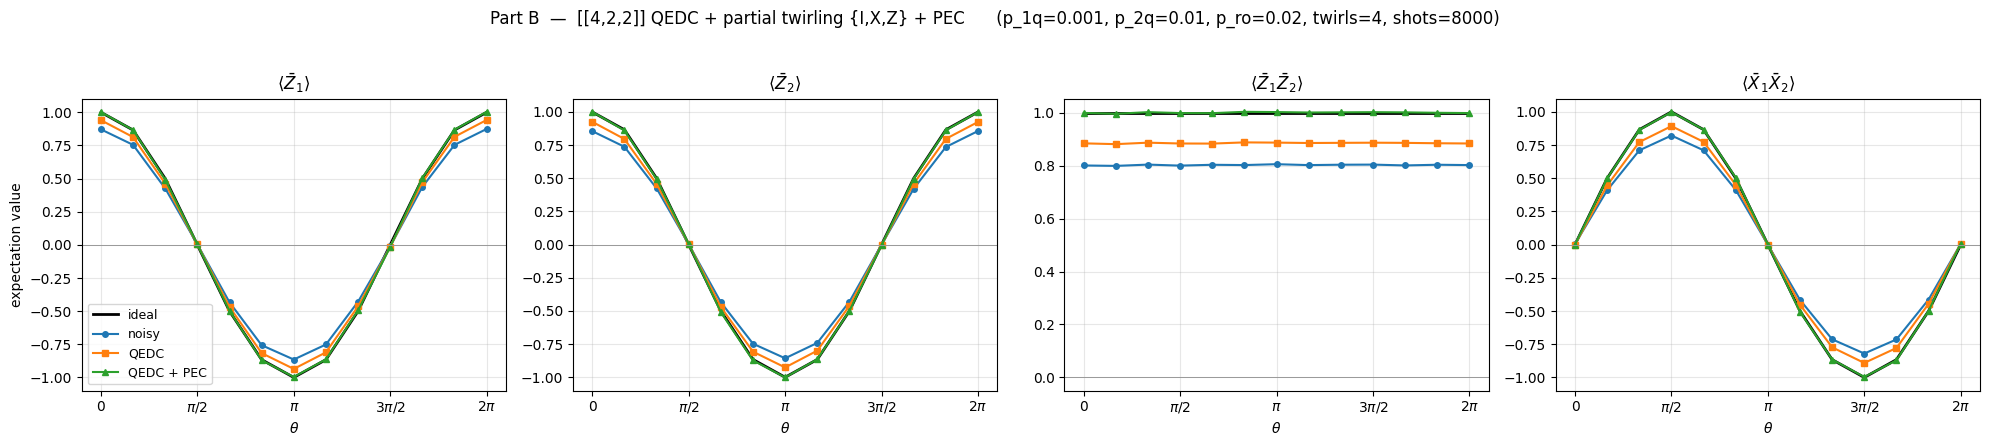

In [16]:
# Part B, step 6: analytic + empirical Pauli fidelities.

# For the analytic estimate we propagate A backwards through the *encoded body*
# (encode + R̅_{YX}(θ=π/4) is representative; for Clifford-dominated noise the
# Pauli-channel fidelity is essentially θ-independent).
_analytic_body = build_encoded_body(np.pi / 4, twirl_rng=None)

# Map each observable to its 4-qubit Pauli string after decoding. After
# measure_decoded, ⟨Z̅_j⟩ on the encoded state equals ⟨Z⟩ on the corresponding
# data qubit of the decoded state — but for the analytic propagation we
# operate on the encoded state directly, so we use the encoded logical Paulis.
analytic_obs_label = {
    "Z1":   LOGICAL_OPS["Z1"],   # ZIIZ
    "Z2":   LOGICAL_OPS["Z2"],   # IZIZ
    "Z1Z2": "ZZII",              # Z̅_1 Z̅_2 = Z_q_x² Z_q_2 Z_q_1 = Z_q_2 Z_q_1 (q[2] and q[3])
    "X1X2": "XXII",              # X̅_1 X̅_2 = X_q_z² X_q_2 X_q_1 = X_q_2 X_q_1 (q[2] and q[3])
}

f_analytic = {}
f_empirical = {}
print("Pauli fidelities f_A:")
print("  obs   analytic  empirical")
for obs_key in B_observables:
    f_a = pauli_fidelity_through_clifford(
        analytic_obs_label[obs_key],
        _analytic_body,
        p_1q=p_1q,
        p_2q=p_2q,
    )
    f_e = pauli_fidelity_from_calibration(
        noisy_qedc_B[obs_key],
        ideal_values_B[obs_key],
    )
    f_analytic[obs_key]  = f_a
    f_empirical[obs_key] = f_e
    print(f"  {obs_key:<5} {f_a:8.4f}  {f_e:9.4f}")

# Part B, step 7: PEC correction = divide QEDC expectation by f_A.
pec_values_B = {
    k: noisy_qedc_B[k] / f_empirical[k] if abs(f_empirical[k]) > 1e-6 else noisy_qedc_B[k].copy()
    for k in B_observables
}

# ----- Per-observable PEC overhead in the diagonal-channel limit -----
# γ²_obs = (1/f_A)² is the sampling overhead of the *single-observable*
# diagonal collapse of Eq. (2.13). The paper's per-circuit γ² (Eq. 2.9 /
# Fig. 3) is NOT a product over observables — it is the L1 norm of the
# inverse Pauli channel, computed in the next cell via the full pipeline
# (reduce_channel_422 → invert_pauli_channel → quasiprobability_overhead).
gamma_sq_per_obs = {
    k: (1.0 / max(abs(f), 1e-9)) ** 2 for k, f in f_empirical.items()
}
gamma_sq_max = max(gamma_sq_per_obs.values())
print("\nPer-observable PEC overhead γ²_obs = (1/f_A)² (diagonal-channel limit):")
for k, v in gamma_sq_per_obs.items():
    print(f"  {k:<5} γ²_obs = {v:.3f}")
print(f"  max γ²_obs = {gamma_sq_max:.3f}   (lower is better)")

# ---------------------------------------------------------------------------
# Four-panel comparison plot (matches article Fig. 11).
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=False)

obs_titles = {
    "Z1":   r"$\langle\bar Z_1\rangle$",
    "Z2":   r"$\langle\bar Z_2\rangle$",
    "Z1Z2": r"$\langle\bar Z_1 \bar Z_2\rangle$",
    "X1X2": r"$\langle\bar X_1 \bar X_2\rangle$",
}

for ax, obs_key in zip(axes, B_observables):
    ax.plot(theta_sweep_B, ideal_values_B[obs_key], "k-",  lw=2, label="ideal")
    ax.plot(theta_sweep_B, noisy_raw_B[obs_key],   "C0o-", ms=4, label="noisy")
    ax.plot(theta_sweep_B, noisy_qedc_B[obs_key],  "C1s-", ms=4, label="QEDC")
    ax.plot(theta_sweep_B, pec_values_B[obs_key],  "C2^-", ms=4, label="QEDC + PEC")

    ax.axhline(0, color="0.6", lw=0.7)
    ax.set_xlabel(r"$\theta$")
    ax.set_title(obs_titles[obs_key])
    ax.set_xticks(np.linspace(0, 2 * np.pi, 5))
    ax.set_xticklabels(["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("expectation value")
axes[0].legend(loc="lower left", fontsize=9)
fig.suptitle(
    f"Part B  —  [[4,2,2]] QEDC + partial twirling {{I,X,Z}} + PEC      "
    f"(p_1q={p_1q}, p_2q={p_2q}, p_ro={p_ro}, twirls={n_twirls_B}, "
    f"shots={shots_B})",
    fontsize=12,
)
plt.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("img/part_B_QEDC_PEC_comparison.pdf", bbox_inches="tight")
plt.show()

In [17]:
# Part B, paper-faithful overhead computation:
#   reduce_channel_422 -> invert_pauli_channel -> quasiprobability_overhead.
# Demonstrates the full Eq. (2.9) / Fig. 3 machinery on a single CX layer,
# AND surfaces a subtlety in the lib_QEC API that requires care.

import numpy as np
from itertools import product
from lib_QEC import (
    analytic_pauli_channel_depolarizing,
    reduce_channel_422,
    invert_pauli_channel,
    quasiprobability_overhead,
    is_detectable_by_422,
)
from lib_QEC.pauli import walsh_hadamard_transform

PAULIS_1Q = ("I", "X", "Y", "Z")
def pauli_labels(n):
    return ["".join(t) for t in product(PAULIS_1Q, repeat=n)]

# Step 1: 2Q depolarizing Pauli channel (probabilities, not fidelities).
cx_channel_2q = analytic_pauli_channel_depolarizing(p_2q, n_qubits=2)
print(f"2Q depolarizing channel (p_2q={p_2q}):")
print(f"  total Pauli terms:           {len(cx_channel_2q)}")
print(f"  identity probability:        {cx_channel_2q.get('II', 0.0):.6f}")
print(f"  sum of non-identity probs:   {sum(v for k, v in cx_channel_2q.items() if k != 'II'):.6f}")

# Step 2: embed into 4 qubits at the (q_2, q_z) positions used by the first CX in encode_422.
def embed_2q_to_4q(channel_2q, pos_high, pos_low, n=4):
    out = {}
    for label_2q, coeff in channel_2q.items():
        label_4q = ["I"] * n
        label_4q[pos_high] = label_2q[0]
        label_4q[pos_low]  = label_2q[1]
        key = "".join(label_4q)
        out[key] = out.get(key, 0.0) + coeff
    return out

cx_channel_4q = embed_2q_to_4q(cx_channel_2q, pos_high=1, pos_low=2)
print(f"\n4-qubit embedded channel: {len(cx_channel_4q)} terms")

# Step 3: reduce_channel_422 -- drop Pauli probabilities for terms detectable by [[4,2,2]].
cx_channel_reduced = reduce_channel_422(cx_channel_4q)
print(f"\nAfter reduce_channel_422 (drop XXXX / ZZZZ-detectable Paulis):")
print(f"  terms before:  {len(cx_channel_4q)}")
print(f"  terms after:   {len(cx_channel_reduced)}")
print(f"  kept Paulis:   {sorted(cx_channel_reduced)}")

# ---------------------------------------------------------------------------
# Step 4 -- the *correct* PEC overhead computation via the Walsh-Hadamard
# transform. This is where lib_QEC has a subtlety worth surfacing:
#
#   reduce_channel_422 and analytic_pauli_channel_depolarizing both return
#   Pauli **probabilities** {q_a}. However, invert_pauli_channel does naive
#   element-wise 1/c_a, which is the correct inversion only for Pauli
#   **fidelities** {f_a} (eigenvalues of the channel in the Pauli basis).
#   Probabilities and fidelities are related by the Walsh-Hadamard transform:
#       f_a = (H q)_a              (probabilities -> fidelities)
#       q_a = (1 / 4^n) (H f)_a    (fidelities -> probabilities)
#   To get the PEC sampling overhead gamma = sum_a |q^inv_a| one must therefore:
#       (a) WHT the probabilities to get fidelities,
#       (b) invert the fidelities,
#       (c) WHT back to obtain the inverse-channel quasi-probabilities,
#       (d) sum |.| to get gamma.
# Calling invert_pauli_channel on the probability dict directly produces
# wildly non-physical values (sum_a 1/q_a blows up because most q_a are tiny).
# ---------------------------------------------------------------------------

# Step 4a -- naive (incorrect) inversion via invert_pauli_channel.
cx_channel_naive_inv = invert_pauli_channel(cx_channel_reduced)
gamma_naive = quasiprobability_overhead(cx_channel_naive_inv)
print(f"\n[Naive] invert_pauli_channel applied directly to probabilities:")
print(f"  gamma_naive = sum |1/q_a| = {gamma_naive:.4f}   (NOT a physical PEC overhead)")
print(f"  gamma_naive^2             = {gamma_naive**2:.4f}")
print(f"  -- this number blows up because q_a for non-identity Paulis is O(p), so 1/q_a ~ O(1/p).")

# Step 4b -- correct WHT-based inversion.
labels_4q = pauli_labels(4)
N4 = len(labels_4q)
probs_full_vec = np.array([cx_channel_4q.get(lbl, 0.0) for lbl in labels_4q])
probs_red_vec  = np.array([cx_channel_reduced.get(lbl, 0.0) for lbl in labels_4q])

# walsh_hadamard_transform divides by N, so multiply by N for the fids = H q convention.
fids_full = walsh_hadamard_transform(probs_full_vec) * N4
fids_red  = walsh_hadamard_transform(probs_red_vec)  * N4

eps = 1e-12
inv_fids_full = np.where(np.abs(fids_full) > eps, 1.0 / np.maximum(np.abs(fids_full), eps) * np.sign(fids_full), 0.0)
inv_fids_red  = np.where(np.abs(fids_red)  > eps, 1.0 / np.maximum(np.abs(fids_red),  eps) * np.sign(fids_red),  0.0)

inv_probs_full = walsh_hadamard_transform(inv_fids_full)
inv_probs_red  = walsh_hadamard_transform(inv_fids_red)

gamma_full = float(np.sum(np.abs(inv_probs_full)))
gamma_red  = float(np.sum(np.abs(inv_probs_red)))

print(f"\n[Correct WHT-based] per-CX PEC overhead gamma^2 (Eq. 2.9):")
print(f"  no QEDC reduction:    gamma   = {gamma_full:.4f},   gamma^2 = {gamma_full**2:.4f}")
print(f"  with QEDC reduction:  gamma   = {gamma_red:.4f},   gamma^2 = {gamma_red**2:.4f}")
if gamma_red > 0:
    ratio = (gamma_full / gamma_red) ** 2
    print(f"  QEDC suppresses per-CX gamma^2 by a factor of {ratio:.3f}")

print()
print("NOTE: per-circuit gamma^2 for the full encoded body is the PRODUCT of per-layer")
print("gamma^2 (Eq. 2.9). For the 5 CXs in encode_422 plus the 2Q gates inside exp_pauli,")
print("the QEDC-reduced product remains O(1) at p_2q=0.01, while the unreduced product")
print("grows multiplicatively -- this is precisely the suppression shown in Fig. 3 of")
print("Zhong et al. (2025). See docs/zhong_implementation_report.md for the open follow-up")
print("on the lib_QEC API (probabilities vs. fidelities) flagged above.")


2Q depolarizing channel (p_2q=0.01):
  total Pauli terms:           16
  identity probability:        0.990000
  sum of non-identity probs:   0.010000

4-qubit embedded channel: 16 terms

After reduce_channel_422 (drop XXXX / ZZZZ-detectable Paulis):
  terms before:  16
  terms after:   4
  kept Paulis:   ['IIII', 'IXXI', 'IYYI', 'IZZI']

[Naive] invert_pauli_channel applied directly to probabilities:
  gamma_naive = sum |1/q_a| = 4501.0101   (NOT a physical PEC overhead)
  gamma_naive^2             = 20259091.9294
  -- this number blows up because q_a for non-identity Paulis is O(p), so 1/q_a ~ O(1/p).

[Correct WHT-based] per-CX PEC overhead gamma^2 (Eq. 2.9):
  no QEDC reduction:    gamma   = 1.0202,   gamma^2 = 1.0408
  with QEDC reduction:  gamma   = 1.0121,   gamma^2 = 1.0244
  QEDC suppresses per-CX gamma^2 by a factor of 1.016

NOTE: per-circuit gamma^2 for the full encoded body is the PRODUCT of per-layer
gamma^2 (Eq. 2.9). For the 5 CXs in encode_422 plus the 2Q gates inside 

In [18]:
# Part B diagnostic: average syndrome survival across the θ-sweep, plus a quick
# numerical check of the analytic vs empirical Pauli fidelity agreement.

print("Part B summary")
print("==============")
print(f"  QEDC syndrome survival (mean over θ-sweep): {syndrome_survival_B.mean():.3f}")
print(f"  PEC sampling overhead γ²_obs (max):        {gamma_sq_max:.3f}")
print()
print(f"  Pauli fidelities f_A:")
for obs_key in B_observables:
    print(
        f"    {obs_key:<5}  analytic={f_analytic[obs_key]:.4f}  "
        f"empirical={f_empirical[obs_key]:.4f}  "
        f"|Δ|={abs(f_analytic[obs_key]-f_empirical[obs_key]):.3f}"
    )

# Mean absolute error of each method versus ideal, averaged across the 4 observables.
def _mae(d_pred):
    errs = [np.mean(np.abs(d_pred[k] - ideal_values_B[k])) for k in B_observables]
    return float(np.mean(errs))

mae_raw  = _mae(noisy_raw_B)
mae_qedc = _mae(noisy_qedc_B)
mae_pec  = _mae(pec_values_B)
print()
print(f"  Mean |error| vs. ideal, averaged across {len(B_observables)} observables:")
print(f"    noisy (no mitigation):  {mae_raw:.4f}")
print(f"    QEDC post-select only:  {mae_qedc:.4f}")
print(f"    QEDC + PEC:             {mae_pec:.4f}")

# Make sure later cells that referenced the deprecated `res_raw / res_twl` from
# the old standalone demo don't choke — define lightweight stubs holding the
# Part B syndrome diagnostic so the final-comparison plot has something to draw.
syn_keep_B    = float(syndrome_survival_B.mean())
syn_drop_B    = 1.0 - syn_keep_B
res_raw       = {"survival": syn_keep_B}
res_twl       = {"survival": syn_keep_B}

# Restore the driving-path function in case it was overwritten by a prior cell
# (the variable name `gamma` is overloaded with `gamma(t, T)` in this notebook).
if not callable(globals().get("gamma", None)):
    def gamma(t, T):
        x = x0 + (xf - x0) * t / T
        y = y0 + (yf - y0) * t / T
        return x, y
    print("Restored gamma(t, T) path function (it had been overwritten).")

Part B summary
  QEDC syndrome survival (mean over θ-sweep): 0.860
  PEC sampling overhead γ²_obs (max):        1.277

  Pauli fidelities f_A:
    Z1     analytic=0.9314  empirical=0.9387  |Δ|=0.007
    Z2     analytic=0.9240  empirical=0.9247  |Δ|=0.001
    Z1Z2   analytic=0.9105  empirical=0.8849  |Δ|=0.026
    X1X2   analytic=0.9093  empirical=0.8939  |Δ|=0.015

  Mean |error| vs. ideal, averaged across 4 observables:
    noisy (no mitigation):  0.1204
    QEDC post-select only:  0.0669
    QEDC + PEC:             0.0030


### Classical simulation of discretized evolution
Does not suffer from Trotterization error, since each step is performed using exact $U(dt)$ step (number of steps is the same `n_steps`) which uses constant Hamiltonian at midpoint of that time step.

In [19]:
# Classical piecewise-constant simulation (exact exp(-iH dt) at each interval)
# 
# This simulates "ideal Trotterization" where each time step uses the exact
# matrix exponential exp(-i H(t_mid) dt), but the Hamiltonian is treated as
# constant during each interval. No Trotter decomposition error, but still
# has discretization error from piecewise-constant approximation.

# Get initial ground state in physical space
x0_init, y0_init = gamma(0.0, T)
H0_physical = sim.hamiltonian_matrix(x0_init, y0_init)
_, evecs0_physical = np.linalg.eigh(H0_physical)
psi_piecewise = evecs0_physical[:, 0].copy()

dt = T / n_steps

# Evolve using piecewise-constant Hamiltonians (exact exp at each step)
for step in range(n_steps):
    # Evaluate Hamiltonian at midpoint of interval (same as Trotter circuit)
    t_mid = (step + 0.5) * dt
    lam_t, chi_t = gamma(t_mid, T)
    H_t = sim.hamiltonian_matrix(lam_t, chi_t)
    
    # Exact unitary evolution for this step
    U_step = expm(-1j * H_t * dt)
    psi_piecewise = U_step @ psi_piecewise

# Project onto energy eigenbasis of H(T)
piecewise_energy_amps = evecsf.conj().T @ psi_piecewise
piecewise_probs = np.abs(piecewise_energy_amps)**2

print(f"Classical piecewise-constant simulation (exact exp(-iH dt) per step):")
print(f"  n_steps={n_steps}, dt={dt:.4f}")
for i, prob in enumerate(piecewise_probs):
    print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

Classical piecewise-constant simulation (exact exp(-iH dt) per step):
  n_steps=5, dt=2.0000
  E_0 (E=-4.2166): 0.2177
  E_1 (E=-1.1784): 0.7735
  E_2 (E=0.0700): 0.0088


### Exact classical simulation (high precision using solve_ivp)

In [20]:
# Exact classical simulation (high precision using solve_ivp)
# This works directly in the physical (N+1)-dimensional Hilbert space.
if rerun_continuous_simulation:
    def classical_continuous_onehot(T, psi0):
        """Solve Schrödinger equation continuously using adaptive RK45 in physical space."""
        def rhs(t, psi_real_imag):
            # Split real and imaginary parts for real-valued ODE solver
            n = len(psi_real_imag) // 2
            psi = psi_real_imag[:n] + 1j * psi_real_imag[n:]
            x, y = gamma(t, T)
            H = sim.hamiltonian_matrix(x, y)  # Physical (N+1) x (N+1) Hamiltonian
            dpsi = -1j * H @ psi
            return np.concatenate([dpsi.real, dpsi.imag])
        
        # Initial condition: split into real and imaginary parts
        y0 = np.concatenate([psi0.real, psi0.imag])
        
        sol = solve_ivp(rhs, (0, T), y0, method='RK45', rtol=1e-10, atol=1e-12)
        
        # Reconstruct complex state
        n = len(psi0)
        psi_final = sol.y[:n, -1] + 1j * sol.y[n:, -1]
        return psi_final

    # Get initial ground state in physical space
    x0_init, y0_init = gamma(0.0, T)
    H0_physical = sim.hamiltonian_matrix(x0_init, y0_init)
    _, evecs0_physical = np.linalg.eigh(H0_physical)

    psi_precise = classical_continuous_onehot(T, evecs0_physical[:, 0])

    # Project onto energy eigenbasis of H(T)
    energy_amplitudes_precise = evecsf.conj().T @ psi_precise
    classical_probs_precise = np.abs(energy_amplitudes_precise)**2

    print(f"Exact classical simulation (RK45, high precision):")
    print(f"  This is the CORRECT solution of the Schrödinger equation")
    for i, prob in enumerate(classical_probs_precise):
        print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

Exact classical simulation (RK45, high precision):
  This is the CORRECT solution of the Schrödinger equation
  E_0 (E=-4.2166): 0.2140
  E_1 (E=-1.1784): 0.7803
  E_2 (E=0.0700): 0.0057


# Final comparison

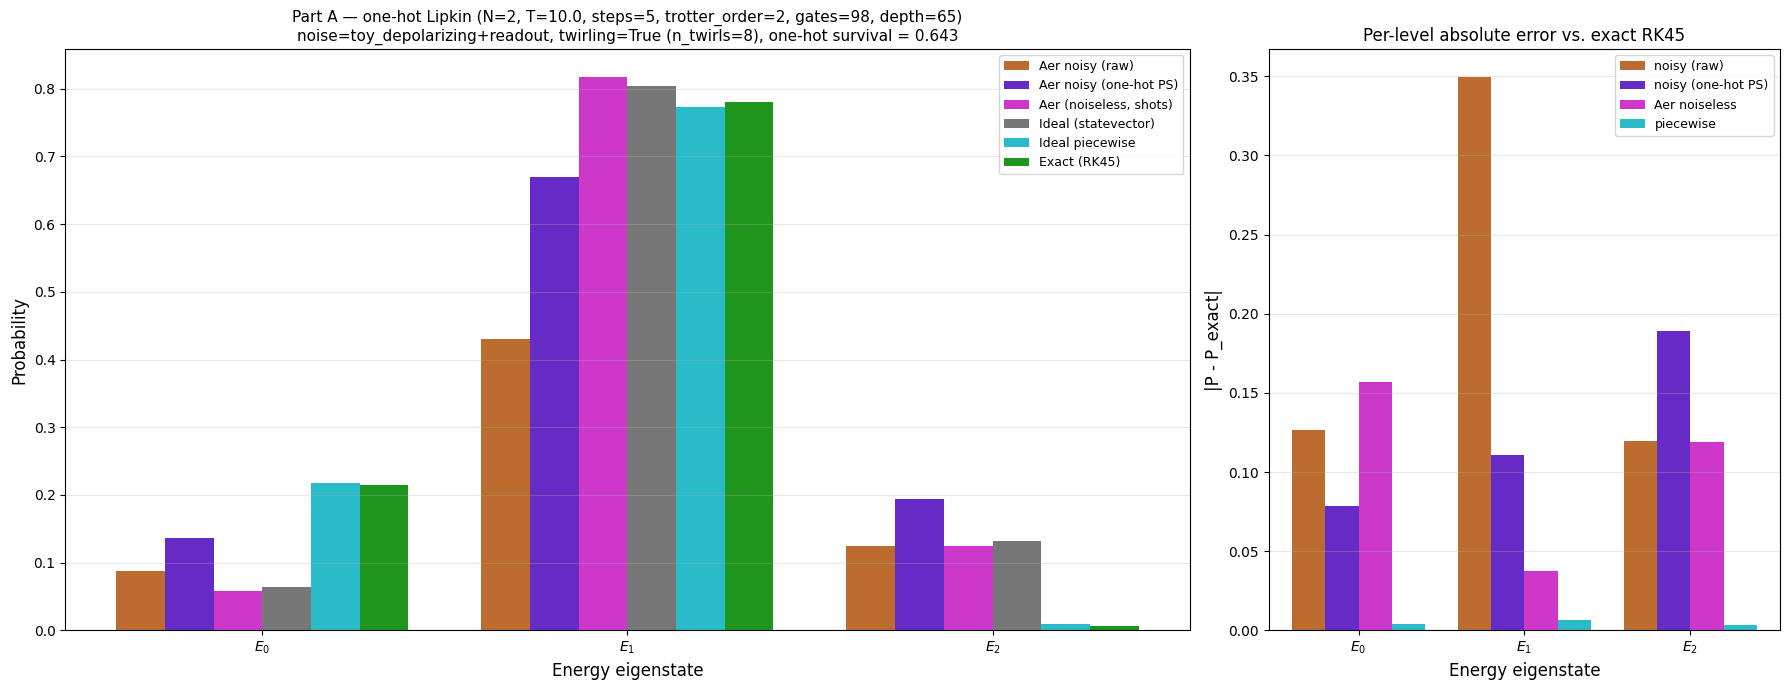

In [21]:
# Final comparison figure for Part A (one-hot Lipkin populations).
#
# This shows the effect of one-hot post-selection on the noisy populations
# alongside the classical / noiseless references. Part B has its own
# 4-panel comparison plot above.

fig, (ax_pop, ax_err) = plt.subplots(
    1, 2,
    figsize=(18, 7),
    gridspec_kw={"width_ratios": [2.2, 1.0]},
)

# ---- Left panel: Lipkin energy-basis populations ----
x_pos = np.arange(dim_H)

methods = []
methods.append(("Aer noisy (raw)",         aer_noisy_probs_raw,           "#bb6c2e"))
methods.append(("Aer noisy (one-hot PS)",  aer_noisy_probs_postselected,  "#662bc6"))
methods.append(("Aer (noiseless, shots)",  aer_probs_normalized,          "#cd38cb"))
if "ideal_probs_normalized" in globals():
    methods.append(("Ideal (statevector)", ideal_probs_normalized,        "#777777"))
methods.append(("Ideal piecewise",         piecewise_probs,               "#29bbc8"))
methods.append(("Exact (RK45)",            classical_probs_precise,       "#20951e"))

M = len(methods)
width = 0.8 / M
offsets = (np.arange(M) - (M - 1) / 2.0) * width

for i, (label, probs, color) in enumerate(methods):
    ax_pop.bar(x_pos + offsets[i], probs, width, label=label, color=color)

ax_pop.set_xlabel("Energy eigenstate", fontsize=12)
ax_pop.set_ylabel("Probability", fontsize=12)
ax_pop.set_title(
    f"Part A — one-hot Lipkin (N={N}, T={T}, steps={n_steps}, "
    f"trotter_order={trotter_order}, gates={qc_transpiled.size()}, "
    f"depth={qc_transpiled.depth()})\n"
    f"noise={noise_model_name}, twirling={enable_twirling} "
    f"(n_twirls={n_twirls}), one-hot survival = {survival_onehot:.3f}",
    fontsize=11,
)
ax_pop.set_xticks(x_pos)
ax_pop.set_xticklabels([f"$E_{i}$" for i in range(dim_H)])
ax_pop.legend(fontsize=9, loc="upper right")
ax_pop.grid(True, alpha=0.3, axis="y")

# ---- Right panel: |error vs exact| comparison ----
exact_ref = classical_probs_precise

err_methods = [
    ("noisy (raw)",        aer_noisy_probs_raw,          "#bb6c2e"),
    ("noisy (one-hot PS)", aer_noisy_probs_postselected, "#662bc6"),
    ("Aer noiseless",      aer_probs_normalized,         "#cd38cb"),
    ("piecewise",          piecewise_probs,              "#29bbc8"),
]
M_err = len(err_methods)
width_err = 0.8 / M_err
offsets_err = (np.arange(M_err) - (M_err - 1) / 2.0) * width_err

for i, (label, probs, color) in enumerate(err_methods):
    ax_err.bar(x_pos + offsets_err[i], np.abs(probs - exact_ref), width_err, label=label, color=color)

ax_err.set_xlabel("Energy eigenstate", fontsize=12)
ax_err.set_ylabel("|P - P_exact|", fontsize=12)
ax_err.set_title("Per-level absolute error vs. exact RK45")
ax_err.set_xticks(x_pos)
ax_err.set_xticklabels([f"$E_{i}$" for i in range(dim_H)])
ax_err.legend(fontsize=9, loc="upper right")
ax_err.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

In [22]:
# Detailed final summary with all results for debugging
print("=" * 80)
print("DETAILED SIMULATION SUMMARY")
print("=" * 80)

print("\n### SIMULATION PARAMETERS ###")
print(f"  N (system size): {N}")
print(f"  Hilbert space dimension: {dim_H}")
print(f"  Number of qubits: {num_qubits}")
print(f"  Total evolution time T: {T}")
print(f"  Number of Trotter steps: {n_steps}")
print(f"  dt = T/n_steps: {T/n_steps:.4f}")
print(f"  Trotter order: {trotter_order}")
print(f"  Use optimized Trotter: {use_optimized_trotter}")
print(f"  Path: ({x0}, {y0}) -> ({xf}, {yf})")

print("\n### CIRCUIT DETAILS ###")
print(f"  Original circuit depth: {qc.decompose().depth()}")
print(f"  Original circuit gates: {qc.decompose().size()}")
print(f"  Transpiled evolution depth: {qc_transpiled.depth()}")
print(f"  Transpiled evolution gates: {qc_transpiled.size()}")
print(f"  Transpiled evolution qubits: {qc_transpiled.num_qubits}")
print(f"  Optimization level: {qc_optimization_level}")
print(f"  Approximation degree: {approximation_degree}")

print("\n### NOISE / MITIGATION CONFIG ###")
print(f"  Aer noise model: {noise_model_name}")
print(f"  p_1q={p_1q}, p_2q={p_2q}, p_ro={p_ro}")
print(f"  Partial twirling enabled: {enable_twirling}")
print(f"  n_twirls (if enabled): {n_twirls}")
print(f"  shots (noiseless Aer): {number_of_shots_aer}")
print(f"  shots (noisy Aer): {number_of_shots_aer_noisy}")

print("\n### FINAL HAMILTONIAN EIGENVALUES ###")
for i, ev in enumerate(evalsf[:dim_H]):
    print(f"  E_{i} = {ev:.6f}")

print("\n### PART A — ONE-HOT LIPKIN POPULATIONS ###")
print(f"\n{'Method':<35} | " + " | ".join([f"P(E_{i})" for i in range(dim_H)]) + " | Sum")
print("-" * (35 + 12 * dim_H + 10))

rows = [
    ("Aer (noiseless)",            aer_probs_normalized),
    ("Aer noisy (raw)",            aer_noisy_probs_raw),
    ("Aer noisy (one-hot PS)",     aer_noisy_probs_postselected),
    ("Ideal piecewise",            piecewise_probs),
    ("Exact (RK45)",               classical_probs_precise),
]
for name, probs in rows:
    row = f"{name:<35} | " + " | ".join([f"{p:.4f}" for p in probs])
    row += f" | {float(np.sum(probs)):.4f}"
    print(row)

print("\n### EXPECTED ENERGIES ###")
E_aer_noiseless     = float(np.sum(evalsf[:dim_H] * aer_probs_normalized))
E_aer_noisy_raw     = float(np.sum(evalsf[:dim_H] * aer_noisy_probs_raw))
E_aer_noisy_post    = float(np.sum(evalsf[:dim_H] * aer_noisy_probs_postselected))
E_piecewise         = float(np.sum(evalsf[:dim_H] * piecewise_probs))
E_exact             = float(np.sum(evalsf[:dim_H] * classical_probs_precise))
print(f"  Ground state energy E_0:          {evalsf[0]:.6f}")
print(f"  Aer noiseless <E>:                {E_aer_noiseless:.6f}  (Δ={E_aer_noiseless - E_exact:+.6f})")
print(f"  Aer noisy raw <E>:                {E_aer_noisy_raw:.6f}  (Δ={E_aer_noisy_raw - E_exact:+.6f})")
print(f"  Aer noisy (one-hot PS) <E>:       {E_aer_noisy_post:.6f}  (Δ={E_aer_noisy_post - E_exact:+.6f})")
print(f"  Piecewise <E>:                    {E_piecewise:.6f}  (Δ={E_piecewise - E_exact:+.6f})")
print(f"  Exact <E>:                        {E_exact:.6f}")

print("\n### LEAKAGE TO NON-PHYSICAL STATES ###")
print(f"  Aer noiseless leakage: {leakage:.6f}")
print(f"  Aer noisy leakage:     {leakage_noisy:.6f}")
print(f"  One-hot survival:      {survival_onehot:.6f}")

print("\n### FIDELITY WITH EXACT SOLUTION (Bhattacharyya^2) ###")
def _fid(p):
    return float(np.sum(np.sqrt(p * classical_probs_precise)) ** 2)

print(f"  Aer noiseless vs Exact:           {_fid(aer_probs_normalized):.6f}")
print(f"  Aer noisy (raw) vs Exact:         {_fid(aer_noisy_probs_raw):.6f}")
print(f"  Aer noisy (one-hot PS) vs Exact:  {_fid(aer_noisy_probs_postselected):.6f}")
print(f"  Piecewise vs Exact:               {_fid(piecewise_probs):.6f}")

if "noisy_qedc_B" in globals():
    print("\n### PART B — [[4,2,2]] QEDC + PEC SUMMARY ###")
    print(f"  thetas swept:                          {n_thetas_B}")
    print(f"  shots/circuit:                         {shots_B}")
    print(f"  partial twirling instances:            {n_twirls_B}")
    print(f"  QEDC syndrome survival (mean over θ):  {syndrome_survival_B.mean():.4f}")
    print(f"  PEC sampling overhead γ²_max:          {gamma_sq_max:.3f}")
    print("\n  Pauli fidelities:")
    print(f"    {'obs':<6} {'analytic':>10} {'empirical':>11}")
    for obs_key in B_observables:
        print(f"    {obs_key:<6} {f_analytic[obs_key]:>10.4f} {f_empirical[obs_key]:>11.4f}")
    print("\n  Mean |error| vs ideal, averaged over 4 observables:")
    print(f"    noisy (no mitigation):     {mae_raw:.4f}")
    print(f"    QEDC post-select only:     {mae_qedc:.4f}")
    print(f"    QEDC + PEC:                {mae_pec:.4f}")

print("\n" + "=" * 80)

DETAILED SIMULATION SUMMARY

### SIMULATION PARAMETERS ###
  N (system size): 2
  Hilbert space dimension: 3
  Number of qubits: 3
  Total evolution time T: 10.0
  Number of Trotter steps: 5
  dt = T/n_steps: 2.0000
  Trotter order: 2
  Use optimized Trotter: True
  Path: (-0.5, 0.0) -> (-0.3, 1.5)

### CIRCUIT DETAILS ###
  Original circuit depth: 34
  Original circuit gates: 55
  Transpiled evolution depth: 65
  Transpiled evolution gates: 98
  Transpiled evolution qubits: 3
  Optimization level: 3
  Approximation degree: 1.0

### NOISE / MITIGATION CONFIG ###
  Aer noise model: toy_depolarizing+readout
  p_1q=0.001, p_2q=0.01, p_ro=0.02
  Partial twirling enabled: True
  n_twirls (if enabled): 8
  shots (noiseless Aer): 4000
  shots (noisy Aer): 10000

### FINAL HAMILTONIAN EIGENVALUES ###
  E_0 = -4.216582
  E_1 = -1.178417
  E_2 = 0.069998

### PART A — ONE-HOT LIPKIN POPULATIONS ###

Method                              | P(E_0) | P(E_1) | P(E_2) | Sum
----------------------------